# RF-DETR Strawberry Detector Training Notebook

This notebook demonstrates how to train the RF-DETR model for strawberry detection using the pepper dataset.

In [17]:
import mlflow
import json
import os
import cv2
import shutil
import random
from datetime import datetime
from rfdetr import RFDETRLarge
from rf_detr_pyfunc import RFDetrPyFuncModel
from mlflow.models import infer_signature

In [ ]:
os.environ["MLFLOW_TRACKING_TOKEN"] = ""

mlflow_config = {
    "experiment_name": "rfdetr_tomato_detector",
    "tracking_uri": "https://gitlab.com/api/v4/projects/72607084/ml/mlflow/",
}

# Hyperparameters
hyperparameters = {
    "base_model_name": "RFDETRMedium",
    "registered_model_name": "rfdetr_tomato_detector",
    "dataset_path": "tomato",
    "output_dir": "output/rfdetr_tomato_detector",
    "epochs": 40,
    "batch_size": 16,
    "grad_accum_steps": 1,
    "device": "cuda",
    "early_stopping": True,
    "early_stopping_patience": 5,
    "early_stopping_use_ema": True,
    "learning_rate": 1e-4,
    "resolution": 448,
}

In [3]:
import matplotlib.pyplot as plt
from pycocotools.coco import COCO
import supervision as sv
import numpy as np

loading annotations into memory...
Done (t=0.03s)
creating index...
index created!


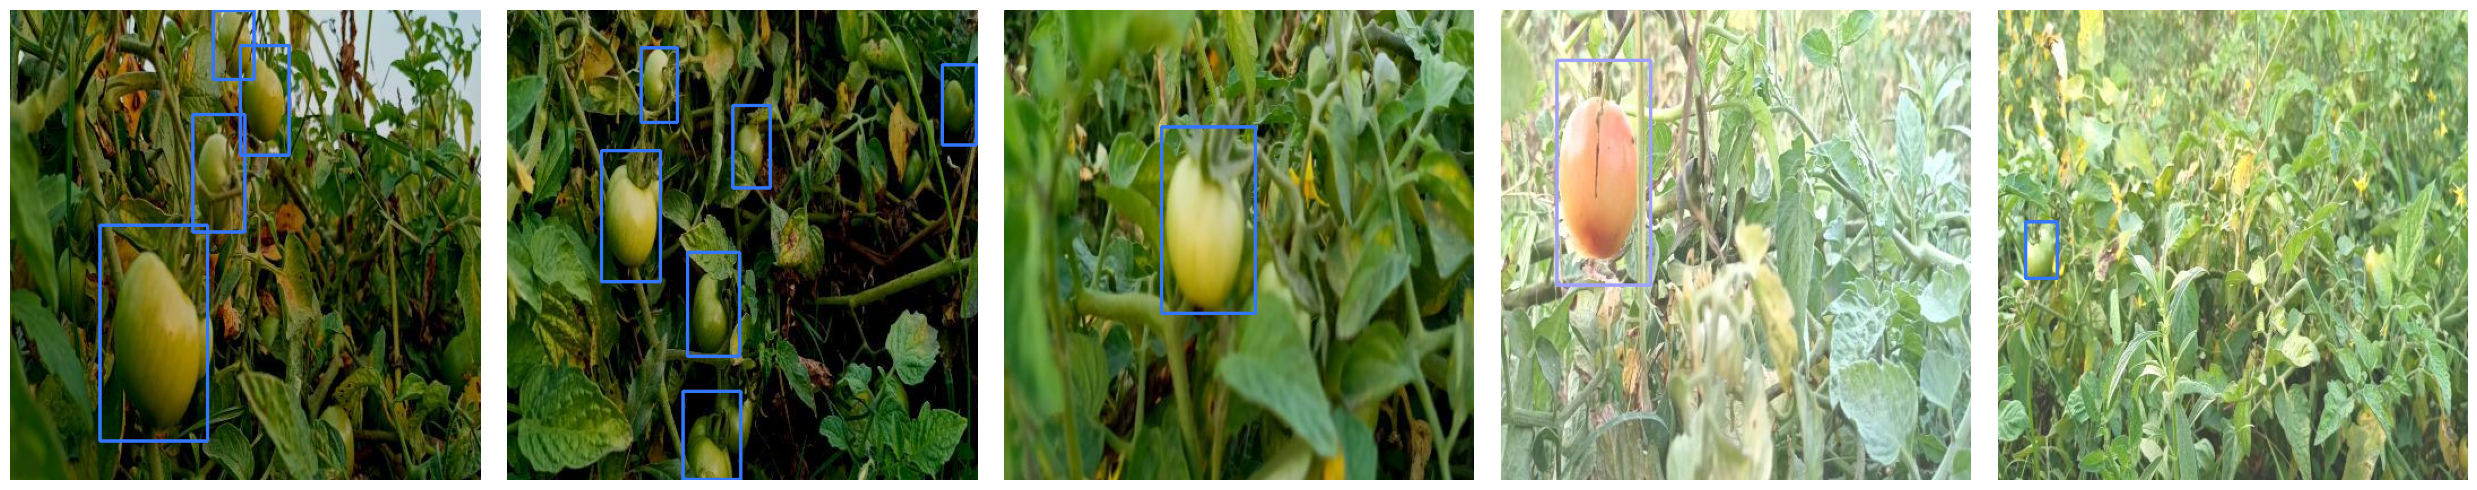

In [5]:
# Visualize samples from the training dataset
coco = COCO(f'{hyperparameters["dataset_path"]}/train/_annotations.coco.json')

# Get some image ids
image_ids = coco.getImgIds()[:5]  # First 5 images

annotated_images = []

for img_id in image_ids:
    img_info = coco.loadImgs(img_id)[0]
    image_path = f"{hyperparameters['dataset_path']}/train/{img_info['file_name']}"
    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    
    # Get annotations
    ann_ids = coco.getAnnIds(imgIds=img_id)
    annotations = coco.loadAnns(ann_ids)
    
    # Convert to supervision detections
    boxes = []
    class_ids = []
    for ann in annotations:
        x, y, w, h = ann['bbox']
        boxes.append([x, y, x+w, y+h])
        class_ids.append(ann['category_id'])
    
    if boxes:
        detections = sv.Detections(
            xyxy=np.array(boxes),
            class_id=np.array(class_ids)
        )
        
        # Visualize
        annotated_image = sv.BoxAnnotator().annotate(image, detections)
    else:
        annotated_image = image
    
    annotated_images.append(annotated_image)

# Display in a grid
num_images = len(annotated_images)
fig, axes = plt.subplots(1, num_images, figsize=(5 * num_images, 5))
if num_images == 1:
    axes = [axes]  # Make it iterable

for i, img in enumerate(annotated_images):
    axes[i].imshow(img)
    axes[i].axis('off')

plt.tight_layout()
plt.show()

In [6]:
def train():
    model = RFDETRLarge()
    model.train(
        dataset_dir=hyperparameters["dataset_path"],
        epochs=hyperparameters["epochs"],
        batch_size=hyperparameters["batch_size"],
        grad_accum_steps=hyperparameters["grad_accum_steps"],
        output_dir=hyperparameters["output_dir"],
        early_stopping=hyperparameters["early_stopping"],
        early_stopping_patience=hyperparameters["early_stopping_patience"],
        lr=hyperparameters["learning_rate"],
        device=hyperparameters["device"],
        early_stopping_use_ema=hyperparameters["early_stopping_use_ema"],
        resolution=hyperparameters["resolution"],
    )

In [8]:
# Train the model
train()

Loading pretrain weights
Unable to initialize TensorBoard. Logging is turned off for this session.  Run 'pip install tensorboard' to enable logging.
Not using distributed mode
git:
  sha: 86c7ec899a0d9031ff6a423a734cbce0ef3a8d6e, status: has uncommited changes, branch: 19-add-notebook-for-training-rfdetr

Namespace(num_classes=4, grad_accum_steps=1, amp=True, lr=0.0001, lr_encoder=0.00015, batch_size=16, weight_decay=0.0001, epochs=40, lr_drop=100, clip_max_norm=0.1, lr_vit_layer_decay=0.8, lr_component_decay=0.7, do_benchmark=False, dropout=0, drop_path=0.0, drop_mode='standard', drop_schedule='constant', cutoff_epoch=0, pretrained_encoder=None, pretrain_weights='rf-detr-large.pth', pretrain_exclude_keys=None, pretrain_keys_modify_to_load=None, pretrained_distiller=None, encoder='dinov2_windowed_base', vit_encoder_num_layers=12, window_block_indexes=None, position_embedding='sine', out_feature_indexes=[2, 5, 8, 11], freeze_encoder=False, layer_norm=True, rms_norm=False, backbone_lora=

Epoch: [0]  [ 0/85]  eta: 0:02:21  lr: 0.000100  class_error: 75.54  loss: 9.5012 (9.5012)  loss_ce: 0.8524 (0.8524)  loss_bbox: 0.6148 (0.6148)  loss_giou: 0.8968 (0.8968)  loss_ce_0: 0.8473 (0.8473)  loss_bbox_0: 0.6263 (0.6263)  loss_giou_0: 0.9443 (0.9443)  loss_ce_1: 0.8531 (0.8531)  loss_bbox_1: 0.6033 (0.6033)  loss_giou_1: 0.8955 (0.8955)  loss_ce_enc: 0.8330 (0.8330)  loss_bbox_enc: 0.6109 (0.6109)  loss_giou_enc: 0.9235 (0.9235)  loss_ce_unscaled: 0.8524 (0.8524)  class_error_unscaled: 75.5359 (75.5359)  loss_bbox_unscaled: 0.1230 (0.1230)  loss_giou_unscaled: 0.4484 (0.4484)  cardinality_error_unscaled: 3859.4375 (3859.4375)  loss_ce_0_unscaled: 0.8473 (0.8473)  loss_bbox_0_unscaled: 0.1253 (0.1253)  loss_giou_0_unscaled: 0.4721 (0.4721)  cardinality_error_0_unscaled: 3891.3750 (3891.3750)  loss_ce_1_unscaled: 0.8531 (0.8531)  loss_bbox_1_unscaled: 0.1207 (0.1207)  loss_giou_1_unscaled: 0.4478 (0.4478)  cardinality_error_1_unscaled: 3882.8125 (3882.8125)  loss_ce_enc_unscale

In [ ]:
def log_experiment():
    """Log experiment details to MLflow."""
    mlflow.set_tracking_uri(mlflow_config["tracking_uri"])
    mlflow.set_experiment(mlflow_config["experiment_name"])

    with mlflow.start_run():
        # Log hyperparameters
        for param, value in hyperparameters.items():
            mlflow.log_param(param, value)

        # Log metrics from output folder
        metric_file = f"{hyperparameters['output_dir']}/log.txt"
        with open(metric_file, "r") as f:
            for line in f:
                dict_line = json.loads(line)

                # Extract and convert timestamp
                timestamp = dict_line.pop("now_time", None)
                timestamp = (
                    int(round(datetime.fromisoformat(timestamp).timestamp()))
                    if timestamp
                    else None
                )

                epoch = dict_line.pop("epoch", None)
                test_results_dict = dict_line.pop("test_results_json", None)

                metrics_to_log = {}

                # Collect time metrics
                for time_key in ["train_epoch_time", "epoch_time"]:
                    if time_value := dict_line.pop(time_key, None):
                        metrics_to_log[time_key] = int(datetime.strptime(time_value, "%H:%M:%S").timestamp())

                # Collect class-specific metrics
                if class_map := test_results_dict.pop("class_map", None):
                    for item in class_map:
                        class_name = item.pop("class")
                        for key, value in item.items():
                            metrics_to_log[f"{class_name}_{key}".replace("@", "_")] = value

                # Remove unwanted keys
                for key in [
                    "ema_test_coco_eval_bbox",
                    "test_coco_eval_bbox",
                    "ema_test_results_json",
                ]:
                    dict_line.pop(key, None)

                # Collect test results
                for key, value in test_results_dict.items():
                    metrics_to_log[key] = value

                # Collect remaining metrics
                for key, value in dict_line.items():
                    metrics_to_log[key] = value

                # Log all metrics in batch
                mlflow.log_metrics(metrics_to_log, step=epoch, timestamp=timestamp)

        # Log artifacts
        mlflow.log_artifact(f"{hyperparameters['output_dir']}/results.json")
        mlflow.log_artifact(f"{hyperparameters['output_dir']}/metrics_plot.png")
        mlflow.log_artifact(metric_file)

        # Log model
        model_path = f"{hyperparameters['output_dir']}/checkpoint_best_total.pth"
        mlflow.log_artifact(model_path, "model_weights")

        # This does not seem to work with gitlab
        
        # # Infer signature
        # model = RFDETRLarge(pretrain_weights=model_path)
        # image = cv2.imread("pepper/train/20251126_082517_jpg.rf.e37936f89aad0ac5902ee100e5f2b97e.jpg")
        # image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        # detections = model.predict(image, threshold=0.5)

        # output_example = {
        #     "boxes": detections.xyxy,
        #     "scores": detections.confidence,
        #     "classes": detections.class_id,
        # }

        # params = {"confidence_threshold": 0.5}

        # signature = infer_signature(image, output_example, params)
        
        # conda_env = {
        #     "channels": ["pytorch", "conda-forge"],
        #     "dependencies": [
        #         "python=3.12.3",
        #         "pip",
        #         "pytorch",
        #         "torchvision",
        #         {
        #             "pip": [
        #                 "mlflow",
        #                 "rfdetr",
        #             ]
        #         },
        #     ],
        #     "name": "mlflow-env",
        # }

        # mlflow.pyfunc.log_model(
        #     python_model=RFDetrPyFuncModel(),
        #     name="rfdetr_pepper_detector_single_class_model",
        #     registered_model_name=hyperparameters["registered_model_name"],
        #     artifacts={"weights": model_path},
        #     conda_env=conda_env,
        #     code_paths=["rf_detr_pyfunc.py"],
        #     signature=signature,
        # )

        # Clean up output directory
        # shutil.rmtree("output")

In [10]:
# Log the experiment to MLflow
log_experiment()

2026/01/07 14:18:50 INFO mlflow.tracking.fluent: Experiment with name 'rfdetr_tomato_detector' does not exist. Creating a new experiment.


🏃 View run polarbear-raccoon-frog-3480 at: https://gitlab.com/api/v4/projects/72607084/ml/mlflow/#/experiments/12/runs/bafe1d13-1d1b-495b-9962-0265becfc496
🧪 View experiment at: https://gitlab.com/api/v4/projects/72607084/ml/mlflow/#/experiments/12


Loading pretrain weights


Model is not optimized for inference. Latency may be higher than expected. You can optimize the model for inference by calling model.optimize_for_inference().


loading annotations into memory...
Done (t=0.01s)
creating index...
index created!


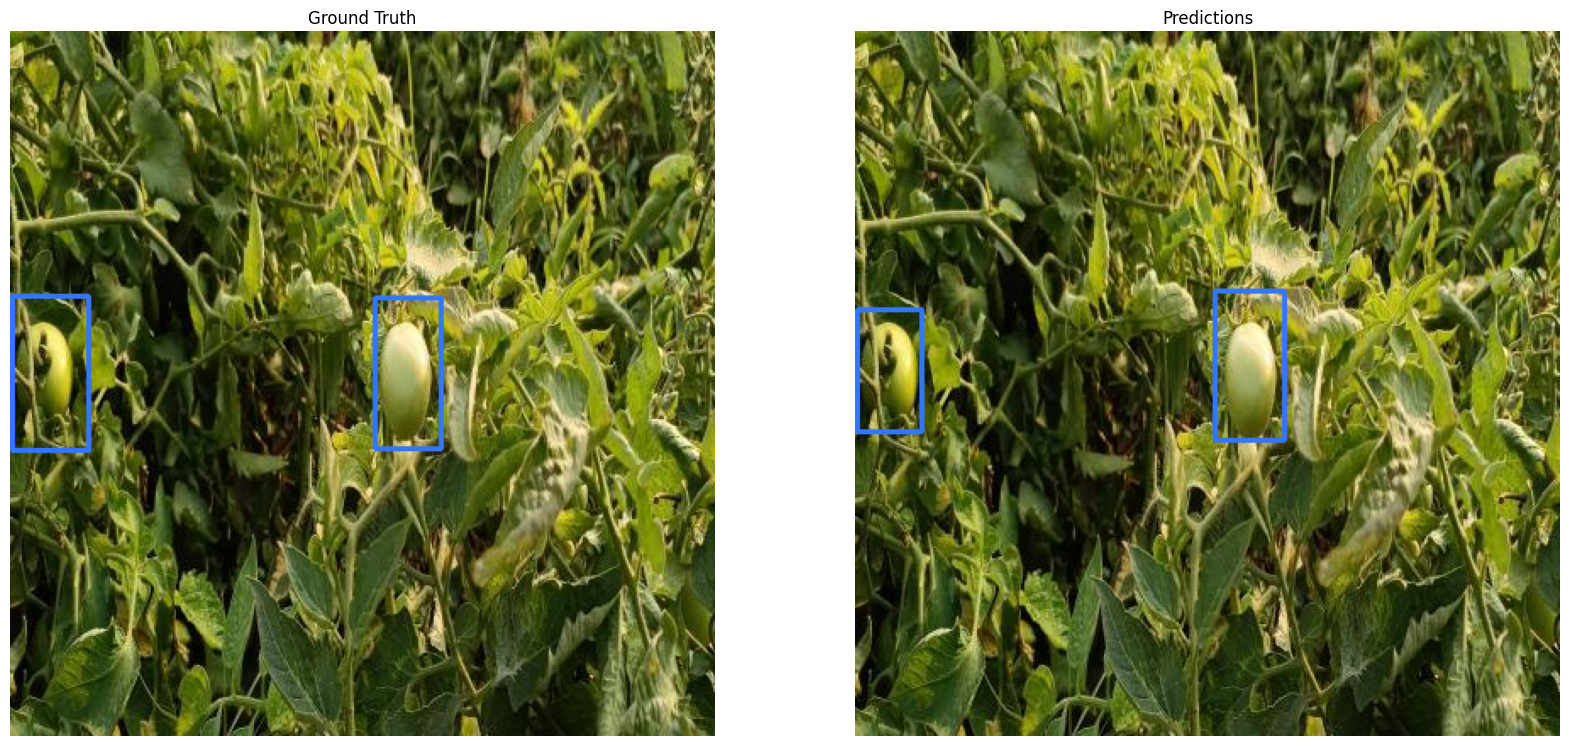

In [18]:
# Inference and visualization
# Load the trained model
model_path = f"{hyperparameters['output_dir']}/checkpoint_best_total.pth"
model = RFDETRLarge(pretrain_weights=model_path)

# Load a random test image from valid
coco_valid = COCO(f'{hyperparameters["dataset_path"]}/valid/_annotations.coco.json')
img_id = random.choice(coco_valid.getImgIds())
img_info = coco_valid.loadImgs(img_id)[0]
image_path = f"{hyperparameters['dataset_path']}/valid/{img_info['file_name']}"
image = cv2.imread(image_path)
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Get ground truth annotations
ann_ids = coco_valid.getAnnIds(imgIds=img_id)
annotations = coco_valid.loadAnns(ann_ids)

# Convert to supervision detections for ground truth
gt_boxes = []
gt_class_ids = []
for ann in annotations:
    x, y, w, h = ann['bbox']
    gt_boxes.append([x, y, x+w, y+h])
    gt_class_ids.append(ann['category_id'])

if gt_boxes:
    gt_detections = sv.Detections(
        xyxy=np.array(gt_boxes),
        class_id=np.array(gt_class_ids)
    )
    gt_annotated = sv.BoxAnnotator().annotate(image_rgb.copy(), gt_detections)
else:
    gt_annotated = image_rgb.copy()

# Predict
detections = model.predict(image_rgb, threshold=0.5)

# Convert to supervision detections for predictions
if len(detections.xyxy) > 0:
    pred_detections = sv.Detections(
        xyxy=detections.xyxy,
        confidence=detections.confidence,
        class_id=detections.class_id
    )
    pred_annotated = sv.BoxAnnotator().annotate(image_rgb.copy(), pred_detections)
else:
    pred_annotated = image_rgb.copy()

# Display side by side
fig, axes = plt.subplots(1, 2, figsize=(20, 10))
axes[0].imshow(gt_annotated)
axes[0].set_title('Ground Truth')
axes[0].axis('off')

axes[1].imshow(pred_annotated)
axes[1].set_title('Predictions')
axes[1].axis('off')

plt.show()